# 02. Ковариационная матрица

$$\Sigma = \frac{1}{T-1} X^\top X, \qquad X = R - \bar R \;\text{(из каждого столбца вычтено среднее)}$$

- Размер: $(N\times T)\cdot(T\times N) = N \times N$ — дни «сворачиваются».
- Элемент $\Sigma_{ij}$ — скалярное произведение столбцов $i$ и $j$ матрицы $X$, делённое на $T-1$.
- Диагональ — дисперсии, вне диагонали — ковариации. Матрица симметрична, потому что $a\cdot b = b\cdot a$.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.precision', 3)
from src.data import *
from src.risk import *
from src.pca import *
from src.plots import *

In [2]:
r = simple_returns(clean_prices(load_prices()))
S = covariance_matrix(r)
print('размер:', S.shape)
print('совпадает с np.cov:', np.allclose(S, np.cov(r.to_numpy(), rowvar=False)))
print('симметрична:', np.allclose(S, S.T))

размер: (27, 27)
совпадает с np.cov: True
симметрична: True


## Почему $v^\top\Sigma v \ge 0$ для любого $v$
$$v^\top X^\top X v = (Xv)^\top(Xv) = y^\top y = \sum_t y_t^2 \ge 0$$
$y = Xv$ — ряд отклонений портфеля с весами $v$ от его среднего. Значит, $v^\top\Sigma v$ — **дисперсия портфеля** $v$, и она не может быть отрицательной (Σ положительно полуопределена). Отсюда же формула риска портфеля $\sigma_p = \sqrt{w^\top\Sigma w}$.

In [3]:
v = np.array([0.5, 0.3, 0.2])
sub = r[['AAPL', 'XOM', 'TLT']]
y = (sub - sub.mean()).to_numpy() @ v
print('vᵀΣv           =', v @ covariance_matrix(sub).to_numpy() @ v)
print('Σ y²/(T−1)     =', (y ** 2).sum() / (len(y) - 1))

vᵀΣv           = 0.00012193555199614975
Σ y²/(T−1)     = 0.00012193555199614973


## Ковариация и корреляция
$$C = D^{-1}\Sigma D^{-1},\quad D = \text{diag}(\sigma_1,\dots,\sigma_N) \quad\Longrightarrow\quad C_{ij} = \frac{\Sigma_{ij}}{\sigma_i\sigma_j}$$
Ковариация смешивает силу связи и «громкость» активов; корреляция оставляет только силу связи (от −1 до +1, без единиц измерения).

In [4]:
C = correlation_from_cov(S)
S_ann = S * TRADING_DAYS
pairs = [('NVDA', 'ORCL'), ('NVDA', 'MSFT'), ('XOM', 'CVX'), ('KO', 'PEP')]
pd.DataFrame({'cov (%²/год)': [S_ann.loc[a, b] * 1e4 for a, b in pairs],
              'corr': [C.loc[a, b] for a, b in pairs]},
             index=[f'{a}–{b}' for a, b in pairs]).round(2)

,cov (%²/год),corr
NVDA–ORCL,961.47,0.42
NVDA–MSFT,817.19,0.56
XOM–CVX,564.06,0.85
KO–PEP,213.05,0.67


In [5]:
(annual_vol(S) * 100).sort_values().round(1).to_frame('годовая волатильность, %')

,"годовая волатильность, %"
TLT,15.7
KO,16.7
JNJ,17.6
PG,18.2
GLD,18.9
PEP,18.9
WMT,22.5
COST,23.0
ABBV,23.3
JPM,24.4


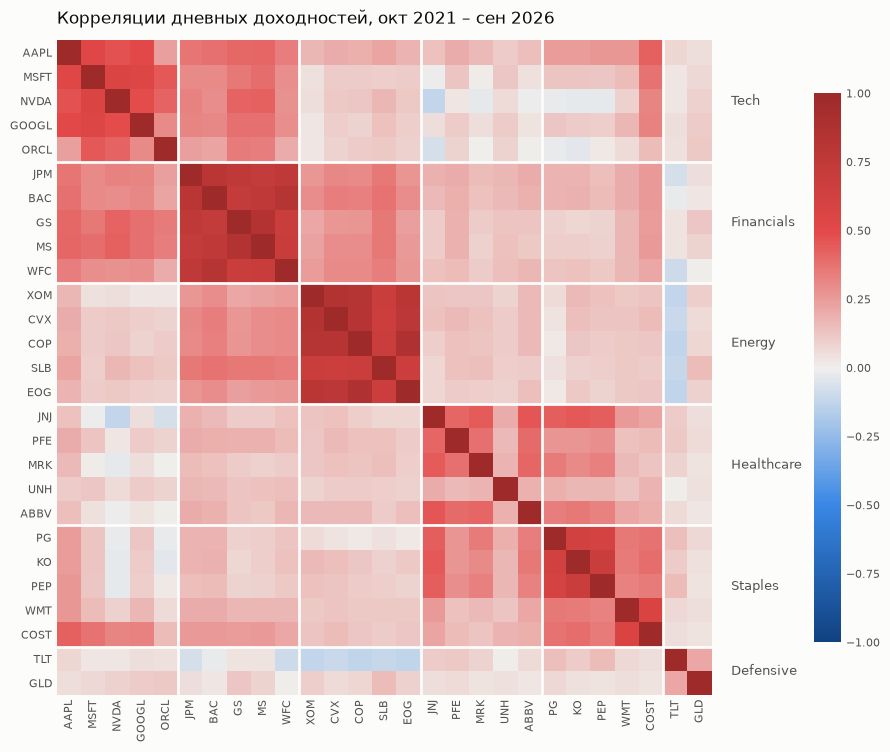

In [6]:
corr_heatmap(C, UNIVERSE, 'Корреляции дневных доходностей, окт 2021 – сен 2026');

In [7]:
sec = pd.Series(SECTOR_OF)
inside = [C.loc[a, b] for a in C for b in C if a < b and sec[a] == sec[b]]
across = [C.loc[a, b] for a in C for b in C if a < b and sec[a] != sec[b]]
print(f'средняя корреляция внутри сектора {np.mean(inside):.2f}, между секторами {np.mean(across):.2f}')

средняя корреляция внутри сектора 0.54, между секторами 0.15


## Диверсификация живёт вне диагонали
$$w^\top\Sigma w = \underbrace{\sum_i w_i^2\Sigma_{ii}}_{\text{диагональ}} + \underbrace{2\sum_{i<j} w_i w_j\Sigma_{ij}}_{\text{вне диагонали}}$$
Для портфеля из $N$ акций с равными весами, средней дисперсией $\sigma^2$ и средней корреляцией $\rho$:
$$\sigma_p^2 = \frac{\sigma^2}{N} + \left(1-\tfrac1N\right)\rho\sigma^2 \;\xrightarrow{N\to\infty}\; \rho\sigma^2$$
Первую часть можно убрать, увеличивая число акций, вторую — общее движение рынка — нельзя.

In [8]:
stocks = TICKERS[:25]
def vol(weights: pd.Series) -> float:
    cov = covariance_matrix(r[weights.index]).to_numpy()
    return np.sqrt(weights @ cov @ weights * TRADING_DAYS)

rows = {'25 акций, равные веса': vol(pd.Series(1 / 25, index=stocks))}
for x in ['KO', 'TLT', 'GLD']:
    rest = [s for s in stocks if s != x]                     # KO уже среди акций — не берём дважды
    rows[f'80% акций + 20% {x}'] = vol(pd.concat([pd.Series(0.8 / len(rest), index=rest), pd.Series({x: 0.2})]))
(pd.Series(rows) * 100).round(1).to_frame('годовая волатильность, %')

,"годовая волатильность, %"
"25 акций, равные веса",14.5
80% акций + 20% KO,13.4
80% акций + 20% TLT,12.1
80% акций + 20% GLD,12.7


KO и TLT почти одинаково волатильны (≈17% и ≈16%), но TLT снижает риск сильнее: его корреляция с акциями ≈0, а у KO ≈0.2. **Помогает не низкая волатильность, а низкая корреляция.**

⚠️ Нулевая корреляция ≠ защита от убытков: в 2022 году TLT потерял около −31% при корреляции с акциями ≈0.

## «Здоровье» матрицы

In [9]:
lam = spectrum(S)
print('все собственные значения > 0:', (lam > 0).all())
print(f'число обусловленности κ = λmax/λmin = {condition_number(S):.0f}')
print(f'T/N = {len(r) / r.shape[1]:.0f}, параметров в Σ: {27 * 28 // 2}')

все собственные значения > 0: True
число обусловленности κ = λmax/λmin = 70
T/N = 46, параметров в Σ: 378


$\kappa$ показывает, во сколько раз обращение $\Sigma^{-1}$ может усилить ошибку во входных данных. При $T/N \approx 46$ Σ обратима и обусловлена умеренно; при $N > T$ она была бы вырождена (rank ≤ T−1).

## Стабильность во времени

In [10]:
h = len(r) // 2
C1, C2 = r.iloc[:h].corr(), r.iloc[h:].corr()
d = (C2 - C1).to_numpy()[np.triu_indices(27, 1)]
print(f'{r.index[0].date()}…{r.index[h-1].date()}  vs  {r.index[h].date()}…{r.index[-1].date()}')
print(f'средний сдвиг корреляции {np.abs(d).mean():.2f}, максимальный {np.abs(d).max():.2f}')
print(f"ORCL–COST: {C1.loc['ORCL', 'COST']:.2f} → {C2.loc['ORCL', 'COST']:.2f}")

2021-10-04…2024-04-01  vs  2024-04-02…2026-09-30
средний сдвиг корреляции 0.13, максимальный 0.47
ORCL–COST: 0.43 → -0.04


**Вывод:** Σ — снимок прошлого, а не закон природы. Всё, что на ней строится (факторы, оптимальный портфель), в будущем будет работать хуже, чем на истории. Проверим это на этапе 5.